<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    One Table of Nodules for LNDb and LIDC IDRI
  </h1>

  <p>
    Everything we model starts from a single table with one row per finding, whichever dataset it comes from. This notebook joins the LNDb table (notebook 01) and the LIDC IDRI table (notebook 02), checks it, and selects from it the <strong>study cohort</strong>: the nodules that the models learn from and are evaluated on.
  </p>
</div>

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
from src.mass_detect.scripts.cohort import select_cohort, suspicious
from src.mass_detect.scripts.config import LIDC_NODULES_FILE, LNDB_NODULES_FILE, NODULE_TABLE
from src.mass_detect.scripts.schema import SCHEMA

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
COLORS = {"LNDb": "blue", "LIDC": "orange"}

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The shared schema
  </h3>
  <p>
    Both datasets are described with the same columns. The ones that matter most for modelling are the position of the nodule in millimetres (<code>x_mm</code>, <code>y_mm</code>, <code>z_mm</code>), its size (<code>diameter_mm</code>), the median rating (<code>mal_median</code>) and the keys that protect us from leakage (<code>scan_id</code>, <code>patient_id</code>). We also keep scanner information (manufacturer, kernel, slice thickness), because the two datasets come from very different acquisition setups.
  </p>
  <p>
    A few conventions are worth knowing:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The unit of analysis is the nodule. The readings of several radiologists are merged into one row, and <code>n_rated</code> keeps how many of them rated it, so that readings can be weighted later.</li>
    <li style="margin-bottom: 8px;">A rating of 0 in LNDb means that the field was not filled in, so it becomes a missing value and not a benign rating.</li>
    <li style="margin-bottom: 8px;"><code>mal_median</code> is the median of the ratings, and the label is that median rounded half up. <code>mal_mean</code> and <code>mal_mode</code> keep the mean and the mode of the same ratings (a tie gives the median of the tied ratings), only to compare ways of combining the readers. Nodules rated 3 are kept, because excluding the indeterminate ones makes the problem look easier than it is (notebook 00).</li>
  </ul>
</div>

In [2]:
# The schema lives in src/mass_detect/scripts/schema.py (together with equivalent_diameter)
print(Path.cwd().parent.joinpath("src", "mass_detect", "scripts", "schema.py").read_text())

"""The shared column schema of the nodule table and the equivalent diameter."""
import math
import numpy as np

SCHEMA = [
    "dataset",                # LNDb or LIDC
    "scan_id",                # unique CT id: LNDb-0001, or the series UID in LIDC
    "patient_id",             # grouping key for validation (in LNDb we assume one CT per patient)
    "nodule_uid",             # unique nodule id across both datasets
    "x_mm", "y_mm", "z_mm",   # nodule centre in world coordinates (mm), in each dataset's own CT frame
    "diameter_mm",            # diameter of the sphere with the same volume as the segmentation
    "volume_mm3",             # mean volume of the segmentation
    "volume_is_placeholder",  # LNDb: 3 mm sphere stored when radiologists only marked a centre
    "is_nodule",              # 1 nodule, 0 non nodule (LIDC only contains nodules of 3 mm or more)
    "mal_median",             # median of the malignancy ratings (1 to 5), the label; NaN when unrated
    "mal_mean", "

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Loading the two tables
  </h3>
  <p>
    The LNDb table is built in notebook 01 and the LIDC IDRI table in notebook 02, where the six LIDC IDRI groups that stayed above four annotations were removed. Each notebook saves its table as a CSV; here we only join them.
  </p>
</div>

In [3]:
lndb = pd.read_csv(LNDB_NODULES_FILE)
lidc = pd.read_csv(LIDC_NODULES_FILE)
print("LNDb rows:", len(lndb), "| LIDC rows:", len(lidc))

LNDb rows: 1219 | LIDC rows: 2657


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Joining the two tables
  </h3>
  <p>
    Because both tables follow the same schema, joining them is a plain concatenation. The checks make sure that the keys are unique, that the ratings are in range and that non nodules never carry a rating. The joined table is saved, because notebooks 04 to 06 read it.
  </p>
</div>

In [4]:
table = pd.concat([lndb, lidc], ignore_index=True)[SCHEMA]

assert table["nodule_uid"].is_unique
assert table["mal_mean"].dropna().between(1, 5).all()
assert (table.loc[table["is_nodule"] == 0, "n_rated"] == 0).all()
assert (table["n_rated"] <= table["n_readings"]).all()
table.to_csv(NODULE_TABLE, index=False)              # read by notebooks 04 to 06
print(f"saved {len(table)} rows -> {NODULE_TABLE.name}")

nodules = table[table["is_nodule"] == 1]
nodules.groupby("dataset").agg(
    nodules=("nodule_uid", "size"),
    patients=("patient_id", "nunique"),
    rated=("mal_mean", "count"),
    median_diameter_mm=("diameter_mm", "median"),
    mean_readers=("n_rated", "mean"),
).round(2)

saved 3876 rows -> nodule_table.csv


,nodules,patients,rated,median_diameter_mm,mean_readers
dataset,,,,,
LIDC,2657,874,2657,6.16,2.57
LNDb,768,212,765,4.94,1.34


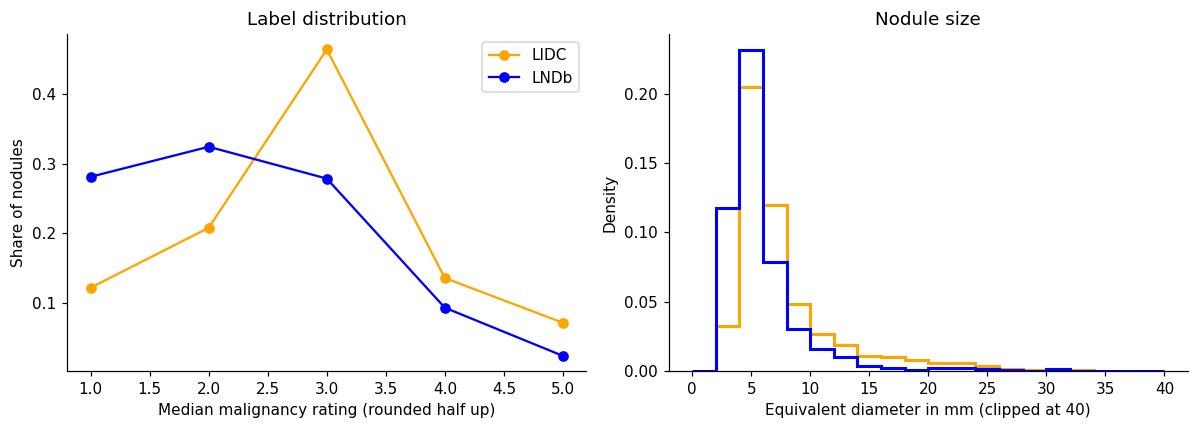

In [5]:
fig, (ax_label, ax_size) = plt.subplots(1, 2, figsize=(11, 4))
for name, group in nodules.groupby("dataset"):
    # Share of each rating, with the median rounded half up (2.5 becomes 3)
    rounded = np.floor(group["mal_median"].dropna() + 0.5)
    share = rounded.value_counts(normalize=True).reindex(range(1, 6), fill_value=0)
    ax_label.plot(share.index, share.values, marker="o", color=COLORS[name], label=name)

    # Distribution of the diameter, with the largest nodules grouped at 40 mm
    diameters = group["diameter_mm"].dropna().clip(upper=40)
    ax_size.hist(diameters, bins=np.arange(0, 41, 2), density=True, histtype="step",
                 linewidth=2, color=COLORS[name], label=name)

ax_label.set(xlabel="Median malignancy rating (rounded half up)", ylabel="Share of nodules", title="Label distribution")
ax_size.set(xlabel="Equivalent diameter in mm (clipped at 40)", ylabel="Density", title="Nodule size")
ax_label.legend()
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The two datasets do not look alike. LNDb leans clearly towards benign ratings, while LIDC IDRI peaks at 3. Part of this comes from combining readers: LIDC IDRI nodules have on average about 2.6 ratings against 1.3 in LNDb, and the median of readers who disagree, for example 2 and 4, tends to land in the middle. LNDb also contains smaller nodules, which explains its smaller median diameter (4.9 against 6.2 mm). Both effects matter when the two datasets are pooled, so a rating of 3 should not be assumed to mean the same thing in both.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The study cohort
  </h3>
  <p>
    A finding enters the study only if it passes every one of these rules, applied in this order:
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>It is a nodule.</strong> Non nodules carry no malignancy rating and are not what the model is asked about.</li>
    <li style="margin-bottom: 8px;"><strong>It has a malignancy rating.</strong> A rating of 0 in LNDb means that the field was not filled in.</li>
    <li style="margin-bottom: 8px;"><strong>It has a radiologist mask, which means it measures 3 mm or more.</strong> The features are computed inside the region drawn by the radiologists. LIDC IDRI only describes nodules of 3 mm or more (Armato et al., 2011), while in LNDb the nodules under 3 mm were only marked with a centre (Pedrosa et al., 2019), so the same rule keeps the two populations comparable. Nodules this small are also of low clinical concern and do not need routine follow up (MacMahon et al., 2017).</li>
    <li style="margin-bottom: 8px;"><strong>Its LIDC IDRI group has at most four annotations.</strong> LIDC IDRI has four radiologists, so a larger group mixes more than one nodule. These groups were already removed in notebook 02, so this rule is a safeguard.</li>
    <li style="margin-bottom: 8px;"><strong>Its LIDC IDRI position was confirmed when the patch was cut.</strong> Notebook 04 computes the centre in two independent ways and keeps the nodules where both agree within 1 mm. Without that check the mask could fall next to the nodule instead of on it.</li>
  </ol>
  <p>
    The label is the <strong>median</strong> of the radiologists' ratings rounded half up, so 2.5 becomes 3. A single reader who disagrees with the others cannot move the median, while it does move the mean, and unlike the mode the median is defined for every nodule without a tie rule. The mean and the mode are kept only to compare ways of combining the readers (notebook 06).
  </p>
  <p>
    We study two scales built from that label. The first is the original 1 to 5 rating. The second is a <strong>binary scale</strong>: a nodule is suspicious when its rating is 4 or 5, and not suspicious when it is 1, 2 or 3. We chose this cut for four reasons:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>It follows the meaning of the rating.</strong> In the scale used by both datasets, 3 means indeterminate, and only 4 (moderately suspicious) and 5 (highly suspicious) express a suspicion of cancer (McNitt-Gray et al., 2007; Armato et al., 2011). The positive class is therefore exactly "the radiologists suspect a cancer".</li>
    <li style="margin-bottom: 8px;"><strong>It answers the question the clinician faces.</strong> A suspicious nodule is sent for further investigation, such as a PET CT or a biopsy, while an indeterminate one is followed with CT scans according to its size (MacMahon et al., 2017). The model answers yes or no, with its probability, and never "indeterminate", which would not help that decision.</li>
    <li style="margin-bottom: 8px;"><strong>It keeps every nodule.</strong> Many studies drop the nodules rated 3 to build a benign against malignant problem (Baltatzis et al., 2021), but that removes exactly the hard cases a clinician meets in practice and makes the results look better than they would be in use.</li>
    <li style="margin-bottom: 8px;"><strong>It never contradicts the 1 to 5 scale.</strong> It is derived from the rounded rating, so a nodule rated 4 or 5 is always suspicious and a nodule rated 3 never is.</li>
  </ul>
  <p>
    The price is imbalance: few nodules are suspicious (counted below), so the binary scale is judged by the area under the ROC curve, sensitivity and specificity rather than accuracy (notebook 06).
  </p>
</div>

In [6]:
# Inclusion rules and labels on both scales: src/mass_detect/scripts/cohort.py
cohort, funnel = select_cohort(table)
print(f"{len(cohort)} nodules from {cohort.patient_id.nunique()} patients")
funnel

3237 nodules from 1062 patients


dataset,LIDC,LNDb,total
all findings,2657,1219,3876
is a nodule,2657,768,3425
has a malignancy rating,2657,765,3422
has a radiologist mask (3 mm or more),2657,622,3279
at most four annotations (LIDC),2657,622,3279
position confirmed in its patch (LIDC),2615,622,3237


In [7]:
# Number of nodules in each class, on the 1 to 5 scale and on the binary scale
scale_5 = cohort.groupby("dataset")["rating"].value_counts().unstack()
binary = cohort.groupby("dataset")["suspicious"].value_counts().unstack().rename(columns={0: "no", 1: "yes"})
labels = pd.concat({"1 to 5": scale_5, "suspicious": binary}, axis=1)
labels.loc["total"] = labels.sum()
labels

1 to 5                      suspicious     
             1    2     3    4    5         no  yes
dataset                                            
LIDC       323  546  1215  355  176       2084  531
LNDb       140  191   203   70   18        534   88
total      463  737  1418  425  194       2618  619

In [8]:
# The median against the mean and the mode: nodules whose label changes, by dataset and number of readers
def changes(group): # How many labels of the group differ from the median, on the 1 to 5 and on the binary scale
    return pd.Series({
        "nodules": len(group),
        "mean, 1 to 5": int((group["rating_mean"] != group["rating"]).sum()),
        "mode, 1 to 5": int((group["rating_mode"] != group["rating"]).sum()),
        "mean, binary": int((suspicious(group["rating_mean"]) != group["suspicious"]).sum()),
        "mode, binary": int((suspicious(group["rating_mode"]) != group["suspicious"]).sum()),
    })

cohort.rename(columns={"n_rated": "readers"}).groupby(["dataset", "readers"]).apply(changes)

nodules  mean, 1 to 5  mode, 1 to 5  mean, binary  \
dataset readers                                                      
LIDC    1            772             0             0             0   
        2            481             0             0             0   
        3            482            75             0            25   
        4            880           174            78            59   
LNDb    1            403             0             0             0   
        2            175             0             0             0   
        3             44             6             0             0   

                 mode, binary  
dataset readers                
LIDC    1                   0  
        2                   0  
        3                   0  
        4                  22  
LNDb    1                   0  
        2                   0  
        3                   0

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The rules leave <strong>3237 nodules from 1062 patients</strong>: 622 from LNDb and 2615 from LIDC IDRI. Most of what is lost are the 143 LNDb nodules under 3 mm, which have no mask; in LIDC IDRI, 42 nodules could not have their position confirmed.
  </p>
  <p>
    Pooling the two datasets brings the most suspicious class from 18 nodules in LNDb alone to 194, which makes it learnable. The two datasets still rate differently: 46% of the LIDC IDRI nodules are rated 3, against 33% in LNDb, and on the binary scale 20% of the LIDC IDRI nodules are suspicious, against 14% in LNDb (619 suspicious nodules in total, one in five). This difference in rating habits is why notebook 06 compares several ways of combining the datasets.
  </p>
  <p>
    The second table shows where the rule that combines the readers matters. With one or two readers the median, the mean and the mode always give the same label, so the choice only concerns the nodules read by three or four radiologists, almost all of them in LIDC IDRI. There the mean gives another label to 249 nodules, and changes the binary answer of 84 of them, because one dissenting reader pulls it towards 3. The mode differs from the median only with four readers, on 78 nodules, and changes the binary answer of 22. In LNDb the rule barely matters: 6 labels change with the mean and none with the mode, and no binary answer changes. Whatever notebook 06 finds when it compares the rules, the difference can only come from these few hundred LIDC IDRI nodules.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The training duplicates
  </h3>
  <p>
    Some LNDb findings of the same CT lie less than 3 mm apart. In the LNDb files each finding comes from merging the readings of several radiologists, and readings are merged only if they agree on the type. When one radiologist marked a structure as a nodule and another marked the same place as a non nodule, the same lesion appears twice. We check what these pairs are.
  </p>
</div>

In [9]:
# Pairs of LNDb findings in the same CT whose centres are less than 3 mm apart
pairs = []
lndb_findings = table[table["dataset"] == "LNDb"]
for scan, group in lndb_findings.groupby("scan_id"):
    centres = group[["x_mm", "y_mm", "z_mm"]].to_numpy()
    distance = cdist(centres, centres)
    np.fill_diagonal(distance, np.inf)          # a finding is not paired with itself
    for i, j in zip(*np.where(np.triu(distance < 3))):
        first, second = group.iloc[i], group.iloc[j]
        pairs.append({
            "a nodule and a non nodule": first["is_nodule"] != second["is_nodule"],
            "rows with a rating": int(pd.notna(first["mal_mean"])) + int(pd.notna(second["mal_mean"])),
        })

pairs = pd.DataFrame(pairs)
print("pairs closer than 3 mm in the same CT:", len(pairs))
pairs.value_counts().rename("pairs").to_frame()

pairs closer than 3 mm in the same CT: 59


,,pairs
a nodule and a non nodule,rows with a rating,
True,1,59


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    All 59 pairs are a nodule and a non nodule, and in every pair only one row has a malignancy rating. The labelled nodules we train on therefore never appear twice, and the unrated twin rows are not used. Validation is also grouped by patient, so even a hidden duplicate would stay on one side of every split.
  </p>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Limits to keep in mind
  </h3>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The datasets do not measure exactly the same thing. LIDC IDRI only contains nodules of 3 mm or more, read by up to four radiologists. LNDb also includes smaller nodules and non nodules, and most of its nodules were read by a single radiologist, so the label is noisier in LNDb.</li>
    <li style="margin-bottom: 8px;">The regrouped LIDC IDRI nodules rest on a heuristic. They are only 20 rows, marked in 'reclustered'. The groups that stayed above four annotations were removed.</li>
    <li style="margin-bottom: 8px;">Coordinates come from each dataset's own frame. They are only meaningful together with their own CT, which is all we need to cut patches.</li>
    <li style="margin-bottom: 8px;">Validation must group by 'patient_id'. Rows from the same patient share scanner and anatomy.</li>
    <li style="margin-bottom: 8px;">Scanners differ a lot. LNDb comes from one hospital and three Siemens models, while LIDC IDRI mixes many vendors. Both datasets are validated, so the effect of pooling them is measured in each one.</li>
  </ol>
</div>